# Projet de recherche sur XAI (Intelligence artificielle) 

## 1. Création du reseau de neurone pour la classification

### a. importation des données et mini analyse


In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [8]:
%pip install interpret

In [6]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
import torch
from torch.utils.data import Dataset, DataLoader
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import accuracy_score, classification_report
from interpret.glassbox import ExplainableBoostingClassifier

In [7]:
df = pd.read_csv('data/xAPI-Edu-Data.xls',sep=',')
df.head(2)

FileNotFoundError: [Errno 2] No such file or directory: 'data/xAPI-Edu-Data.xls'

In [ ]:
print(df.shape)

(480, 17)


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 480 entries, 0 to 479
Data columns (total 17 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   gender                    480 non-null    object
 1   NationalITy               480 non-null    object
 2   PlaceofBirth              480 non-null    object
 3   StageID                   480 non-null    object
 4   GradeID                   480 non-null    object
 5   SectionID                 480 non-null    object
 6   Topic                     480 non-null    object
 7   Semester                  480 non-null    object
 8   Relation                  480 non-null    object
 9   raisedhands               480 non-null    int64 
 10  VisITedResources          480 non-null    int64 
 11  AnnouncementsView         480 non-null    int64 
 12  Discussion                480 non-null    int64 
 13  ParentAnsweringSurvey     480 non-null    object
 14  ParentschoolSatisfaction  

In [ ]:
df.describe()

,raisedhands,VisITedResources,AnnouncementsView,Discussion
count,480.000000,480.000000,480.000000,480.000000
mean,46.775000,54.797917,37.918750,43.283333
std,30.779223,33.080007,26.611244,27.637735
min,0.000000,0.000000,0.000000,1.000000
25%,15.750000,20.000000,14.000000,20.000000
50%,50.000000,65.000000,33.000000,39.000000
75%,75.000000,84.000000,58.000000,70.000000
max,100.000000,99.000000,98.000000,99.000000


In [ ]:
df.isnull().sum()

gender                      0
NationalITy                 0
PlaceofBirth                0
StageID                     0
GradeID                     0
SectionID                   0
Topic                       0
Semester                    0
Relation                    0
raisedhands                 0
VisITedResources            0
AnnouncementsView           0
Discussion                  0
ParentAnsweringSurvey       0
ParentschoolSatisfaction    0
StudentAbsenceDays          0
Class                       0
dtype: int64

</br>

### b. preparation des données 

=> Encoder les valeurs

In [ ]:
X = df.drop(columns=['Class']).copy()
y = df['Class']  # L, M, H
print("Colonnes de X :", X.columns.tolist())

Colonnes de X : ['gender', 'NationalITy', 'PlaceofBirth', 'StageID', 'GradeID', 'SectionID', 'Topic', 'Semester', 'Relation', 'raisedhands', 'VisITedResources', 'AnnouncementsView', 'Discussion', 'ParentAnsweringSurvey', 'ParentschoolSatisfaction', 'StudentAbsenceDays']


In [ ]:
# pour les les variables binaire plus facile de le faire manuellement 
X['gender'] = X['gender'].map({'M': 0, 'F': 1})
X['Semester'] = X['Semester'].map({'F': 0, 'S': 1})
X['Relation'] = X['Relation'].map({'Father': 0, 'Mum': 1})
X['ParentAnsweringSurvey'] = X['ParentAnsweringSurvey'].map({'No': 0, 'Yes': 1})
X['ParentschoolSatisfaction'] = X['ParentschoolSatisfaction'].map({'Bad': 0, 'Good': 1})
X['StudentAbsenceDays'] = X['StudentAbsenceDays'].map({'Under-7': 0, 'Above-7': 1})

# pour les variables avec un ordre on encode aussi à la main 
stage_map = {'lowerlevel': 1, 'MiddleSchool': 2, 'HighSchool': 3}
X['StageID'] = X['StageID'].map(stage_map)
X['GradeID'] = X['GradeID'].astype(str)
X['GradeID'] = X['GradeID'].str.replace('G-', '', regex=False)
X['GradeID'] = X['GradeID'].astype(int)


# pour les variables nominales avec plusieurs catégorie on utilise un encoder 
one_hot_cols = ['NationalITy', 'PlaceofBirth', 'SectionID', 'Topic']
X = pd.get_dummies(X, columns=one_hot_cols, drop_first=True)

# mais vu que ca donne des boolens qui pose probleme apres cuqnad on veut passer en tenseur
bool_cols = X.select_dtypes(include='bool').columns
X[bool_cols] = X[bool_cols].astype(int)

# pour la cilbe 
y_map = {'L': 0, 'M': 1, 'H': 2}
y_encoded = y.map(y_map)

df_encoded = pd.concat([X, y_encoded.rename('Class')], axis=1)

#print(df_encoded.head())

In [ ]:
print(df_encoded.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 480 entries, 0 to 479
Data columns (total 52 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   gender                    480 non-null    int64
 1   StageID                   480 non-null    int64
 2   GradeID                   480 non-null    int64
 3   Semester                  480 non-null    int64
 4   Relation                  480 non-null    int64
 5   raisedhands               480 non-null    int64
 6   VisITedResources          480 non-null    int64
 7   AnnouncementsView         480 non-null    int64
 8   Discussion                480 non-null    int64
 9   ParentAnsweringSurvey     480 non-null    int64
 10  ParentschoolSatisfaction  480 non-null    int64
 11  StudentAbsenceDays        480 non-null    int64
 12  NationalITy_Iran          480 non-null    int64
 13  NationalITy_Iraq          480 non-null    int64
 14  NationalITy_Jordan        480 non-null    

In [ ]:
X = df_encoded.drop(columns=['Class']).values
y = df_encoded['Class'].values

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.3, random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42
)

print(f"Taille de train : {X_train.shape}, {y_train.shape}")
print(f"Taille de val   : {X_val.shape}, {y_val.shape}")
print(f"Taille de test  : {X_test.shape}, {y_test.shape}")

Taille de train : (336, 51), (336,)
Taille de val   : (72, 51), (72,)
Taille de test  : (72, 51), (72,)


</br>Création des dataloader => pour créer le dataset on doit passer les données en tensuers au réseaux de neurones

In [ ]:
class StudentDataset(Dataset):
    def __init__(self, X_data, y_data):
        self.X = torch.tensor(X_data, dtype=torch.float32)
        self.y = torch.tensor(y_data, dtype=torch.long)  

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

# creation des dataset 
train_data = StudentDataset(X_train, y_train)
val_data   = StudentDataset(X_val,   y_val)
test_data  = StudentDataset(X_test,  y_test)

# création des dataloader pour batcher les données apres 
train_loader = DataLoader(train_data, batch_size=16, shuffle=True)
val_loader   = DataLoader(val_data,   batch_size=16, shuffle=False)
test_loader  = DataLoader(test_data,  batch_size=16, shuffle=False)

print(train_loader)


### c. creation du modele

In [ ]:
class SimpleNN(nn.Module):
    def __init__(self, input_dim, hidden_dim=64, output_dim=3):
        super(SimpleNN, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, output_dim)
        )
        
    def forward(self, x):
        return self.net(x) 

input_dim = X_train.shape[1]  # recup le nb de features 
model = SimpleNN(input_dim=input_dim, hidden_dim=32, output_dim=3)

criterion = nn.CrossEntropyLoss()  
optimizer = optim.Adam(model.parameters(), lr=0.001)


In [ ]:
epochs = 40
for epoch in range(epochs):
    # d abord l'entraînement 
    model.train()
    total_loss = 0.0
    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()
        outputs = model(X_batch)        
        loss = criterion(outputs, y_batch) 
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    train_loss = total_loss / len(train_loader)
    
    # apres la validation
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for X_valb, y_valb in val_loader:
            val_outputs = model(X_valb)
            v_loss = criterion(val_outputs, y_valb)
            val_loss += v_loss.item()
    val_loss /= len(val_loader)
    
    print(f"Epoch [{epoch+1}/{epochs}]  Train Loss: {train_loss:.4f}  Val Loss: {val_loss:.4f}")


Epoch [1/40]  Train Loss: 1.7371  Val Loss: 1.3668
Epoch [2/40]  Train Loss: 1.0813  Val Loss: 1.0754
Epoch [3/40]  Train Loss: 0.9389  Val Loss: 1.0103
Epoch [4/40]  Train Loss: 0.8924  Val Loss: 0.9991
Epoch [5/40]  Train Loss: 0.8746  Val Loss: 0.9504
Epoch [6/40]  Train Loss: 0.8384  Val Loss: 0.9145
Epoch [7/40]  Train Loss: 0.8218  Val Loss: 0.8983
Epoch [8/40]  Train Loss: 0.7731  Val Loss: 0.8994
Epoch [9/40]  Train Loss: 0.7708  Val Loss: 0.8407
Epoch [10/40]  Train Loss: 0.7336  Val Loss: 0.8455
Epoch [11/40]  Train Loss: 0.7238  Val Loss: 0.8342
Epoch [12/40]  Train Loss: 0.7064  Val Loss: 0.8473
Epoch [13/40]  Train Loss: 0.7059  Val Loss: 0.7953
Epoch [14/40]  Train Loss: 0.7143  Val Loss: 0.8169
Epoch [15/40]  Train Loss: 0.6632  Val Loss: 0.7773
Epoch [16/40]  Train Loss: 0.6468  Val Loss: 0.7791
Epoch [17/40]  Train Loss: 0.6342  Val Loss: 0.7646
Epoch [18/40]  Train Loss: 0.6297  Val Loss: 0.7559
Epoch [19/40]  Train Loss: 0.6327  Val Loss: 0.7667
Epoch [20/40]  Train 

In [ ]:
# on teste notre model sut le dataset de test 
model.eval()
all_preds = []
all_true = []

with torch.no_grad():
    for X_t, y_t in test_loader:
        logits = model(X_t)
        preds = torch.argmax(logits, dim=1) 
        all_preds.extend(preds.numpy())
        all_true.extend(y_t.numpy())

acc = accuracy_score(all_true, all_preds)
print("Accuracy test :", acc)

print("Rapport de classification :")
print(classification_report(all_true, all_preds))

Accuracy test : 0.7777777777777778
Rapport de classification :
              precision    recall  f1-score   support

           0       0.83      0.83      0.83        24
           1       0.76      0.76      0.76        34
           2       0.71      0.71      0.71        14

    accuracy                           0.78        72
   macro avg       0.77      0.77      0.77        72
weighted avg       0.78      0.78      0.78        72



# 2. IA explicative : méthode post hoc

## LIME 

In [29]:
from lime import lime_tabular
import torch.nn.functional as F
import lime.lime_tabular


In [33]:
def predict_proba_lime(X_array):
    X_t = torch.tensor(X_array, dtype=torch.float32)
    with torch.no_grad():
        logits = model(X_t) 
        probs = F.softmax(logits, dim=1) 
    return probs.numpy()

# on a en besoin pour apres les faire afficher sur les resultats des méthodes explicable 
feature_names = df_encoded.drop(columns=['Class']).columns.tolist() 
class_names = ["L", "M", "H"]  

# on initialise LIME 
explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=X_train,    
    feature_names=feature_names,
    class_names=class_names,
    verbose=True,
    mode='classification'
)

# on selectionne l echantillon a expliquer (faudrait voir si on peut pas pour toutes les méthodes expliquer le meme echantillon sinon 
# on peut pas vraiement comparer
sample_idx = 20
x_sample = X_test[sample_idx] 

# génération de l explication 
explanation = explainer.explain_instance(
    data_row=x_sample,
    predict_fn=predict_proba_lime, 
    num_features=5  
)
explanation.show_in_notebook(show_table=True)


Intercept 0.7057328307986716
Prediction_local [0.5768595]
Right: 0.2567257


### B. SHAP

In [37]:
import torch.nn.functional as F
import shap

In [39]:
def predict_proba_shap(X_array):
    X_t = torch.tensor(X_array, dtype=torch.float32)
    with torch.no_grad():
        logits = model(X_t)
        probs = F.softmax(logits, dim=1)
    return probs.numpy()

In [41]:
background = X_train[:100]

explainer = shap.KernelExplainer(
    model = predict_proba_shap,
    data = background
)

to_explain = X_test[:20] # comme pour lIME

shap_values = explainer.shap_values(to_explain)

print(" prob avec shap_values :", type(shap_values))
if isinstance(shap_values, list):
    print("longueur de shap_values (nb de classes) =", len(shap_values))
    print("shap_values[0].shape =", shap_values[0].shape)
else:
    print("shap_values.shape =", shap_values.shape)

print("to_explain.shape =", to_explain.shape)




100%|███████████████████████████████████████████| 20/20 [00:13<00:00,  1.45it/s]

 prob avec shap_values : <class 'numpy.ndarray'>
shap_values.shape = (20, 51, 3)
to_explain.shape = (20, 51)


In [61]:
#  => mettre à 20 comment LIME defait plus haut (à mettre la variable en globale)
echantillion = 10
probs = predict_proba_shap(to_explain)  
predicted_class = np.argmax(probs[echantillion])  # pour un echnatillon on garde la classe avec la proba la + haute 

print(f"Classe prédite pour l’échantillon {echantillion} : {class_names[predicted_class]}")

shap.initjs()
shap.force_plot(
    base_value=explainer.expected_value[predicted_class], 
    shap_values=shap_values[echantillion, :, predicted_class],  
    features=to_explain[echantillion],
    feature_names=feature_names
)


Classe prédite pour l’échantillon 10 : H


## Integrated Gradients vs DeepLIFT

/Users/myriam/Desktop/pom/exemple/educ/lib/python3.12/site-packages/captum/_utils/gradient.py:57: UserWarning: Input Tensor 0 did not already require gradients, required_grads has been set automatically.
  warnings.warn(
/Users/myriam/Desktop/pom/exemple/educ/lib/python3.12/site-packages/captum/attr/_core/deep_lift.py:304: UserWarning: Setting forward, backward hooks and attributes on non-linear
               activations. The hooks and attributes will be removed
            after the attribution is finished
  warnings.warn(


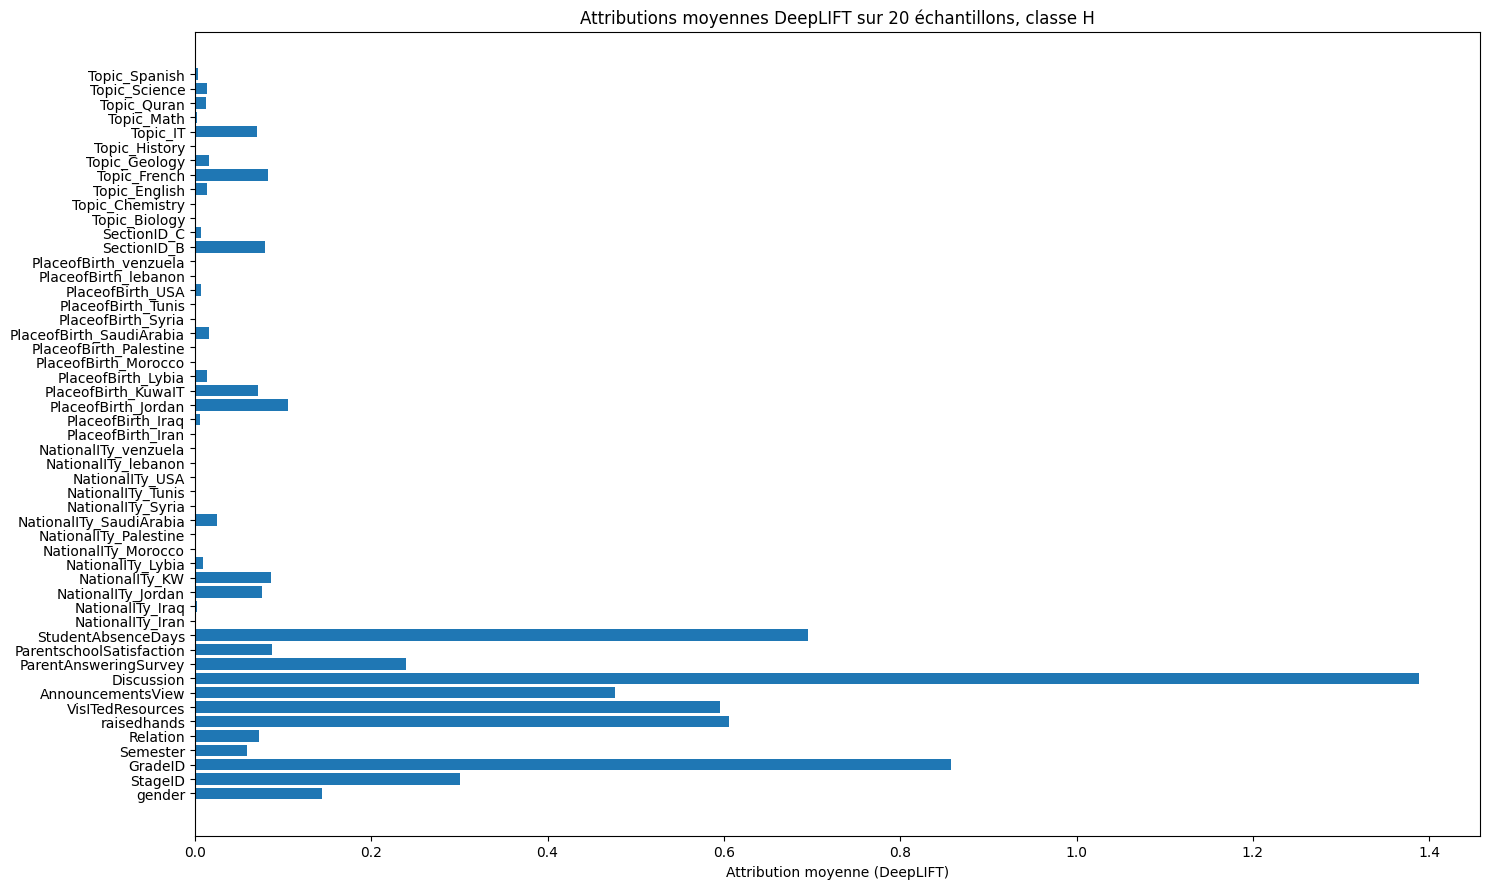

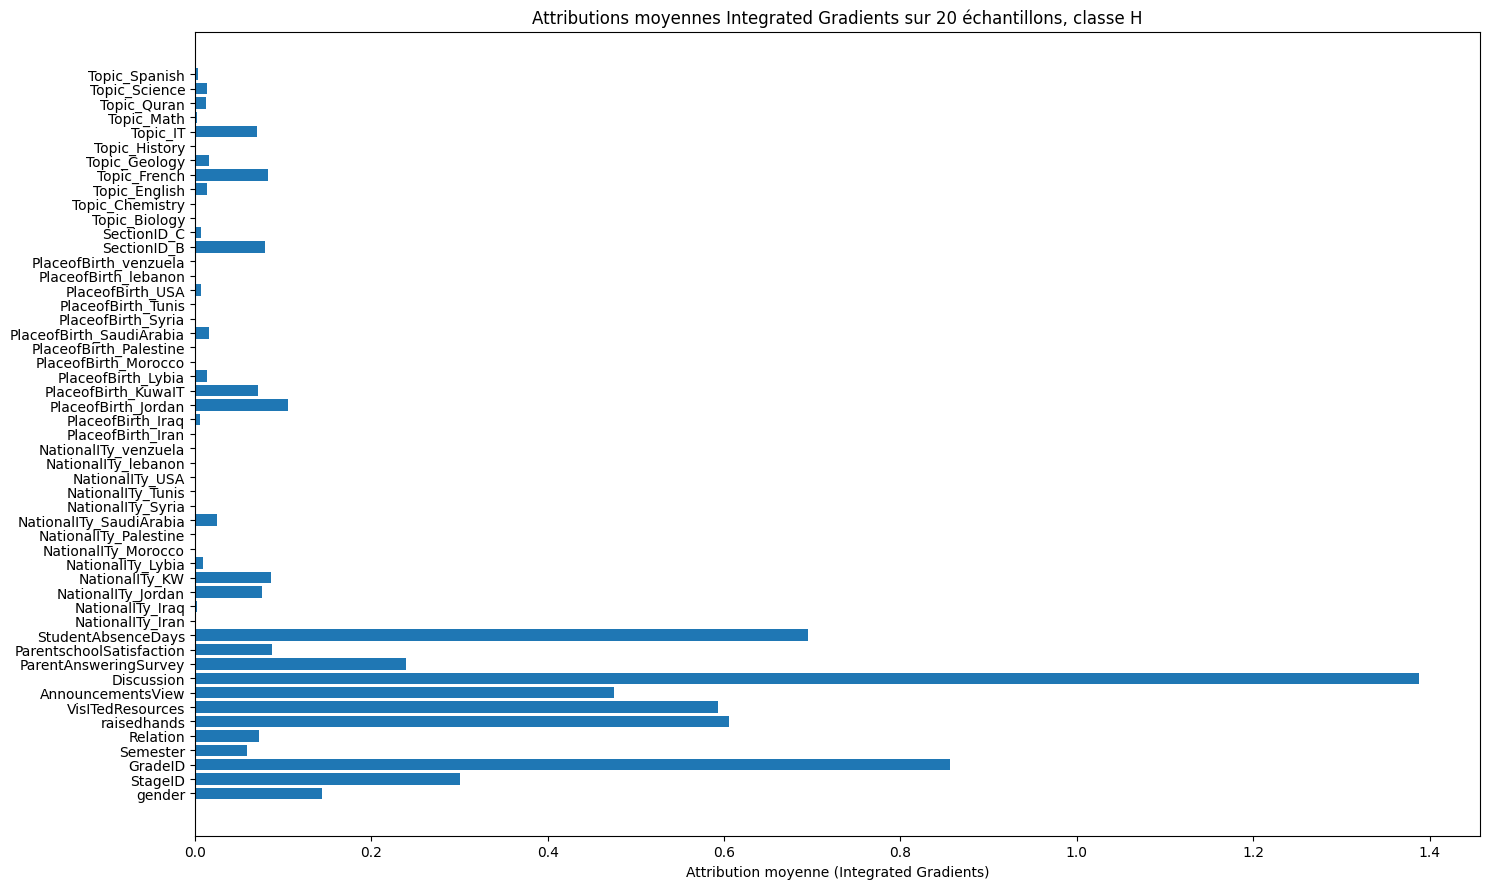

In [63]:
from captum.attr import DeepLift, IntegratedGradients

# 1. DeepLift
model.eval()

actual_feature_names = df_encoded.drop(columns=['Class']).columns.tolist()

# Choix du nombre d'échantillons à analyser et de la classe cible
N = 20  # nb echantillons de test 
target_class = 2 

dl = DeepLift(model)
all_attrs_dl = []
for i in range(N):
    sample = torch.tensor(X_test[i:i+1], dtype=torch.float32)
    baseline = torch.zeros_like(sample)
    attr_sample = dl.attribute(sample, baselines=baseline, target=target_class) # pour calculer les attribution pour la classe cible 
    all_attrs_dl.append(attr_sample.squeeze().detach().numpy()) # extrait le vecteur de shape

all_attrs_dl = np.array(all_attrs_dl)  
mean_abs_attrs_dl = np.mean(np.abs(all_attrs_dl), axis=0) # moyenne des attribution pour chaque caractéristiques 

plt.figure(figsize=(15,9))
plt.barh(actual_feature_names, mean_abs_attrs_dl)
plt.xlabel("Attribution moyenne (DeepLIFT)")
plt.title(f"Attributions moyennes DeepLIFT sur {N} échantillons, classe {class_names[target_class]}")
plt.tight_layout()
plt.show()

# 2. Integrated Gradients
ig = IntegratedGradients(model)
all_attrs_ig = []
for i in range(N):
    sample = torch.tensor(X_test[i:i+1], dtype=torch.float32)
    baseline = torch.zeros_like(sample)
    attr_sample = ig.attribute(sample, baselines=baseline, target=target_class)
    all_attrs_ig.append(attr_sample.squeeze().detach().numpy())

all_attrs_ig = np.array(all_attrs_ig)
mean_abs_attrs_ig = np.mean(np.abs(all_attrs_ig), axis=0)

#plt.figure(figsize=(10, len(actual_feature_names)*0.3))
plt.figure(figsize=(15,9))
plt.barh(actual_feature_names, mean_abs_attrs_ig)
plt.xlabel("Attribution moyenne (Integrated Gradients)")
plt.title(f"Attributions moyennes Integrated Gradients sur {N} échantillons, classe {class_names[target_class]}")
plt.tight_layout()
plt.show()


# 3. IA explicative : approche intreseque

=> implémentation d un Shallow MLP (reseaux de neurone peu profond
-> une seule couche cachée : plus facile à interpréter

Classe prédite pour l'étudiant 9 : L


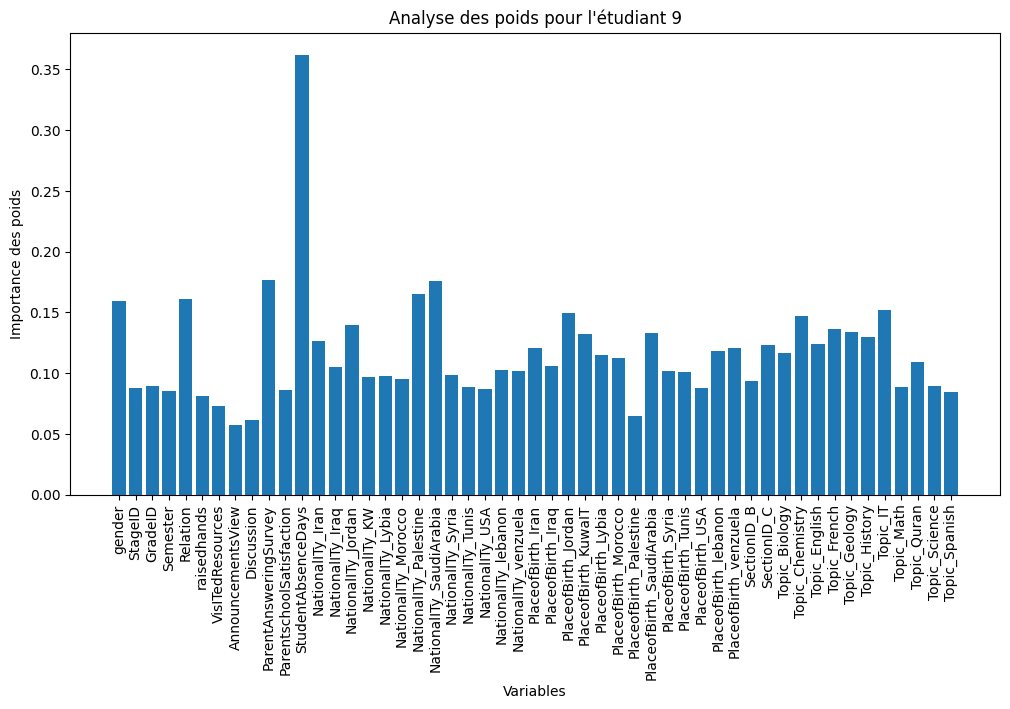

In [73]:
sample_idx = 9  # on selctionne un étudiant 
X_sample = torch.tensor(X_test[sample_idx:sample_idx+1], dtype=torch.float32)

model.eval()
with torch.no_grad():
    output = model(X_sample)
    predicted_class = torch.argmax(output, dim=1).item()

print(f"Classe prédite pour l'étudiant {sample_idx} : {class_names[predicted_class]}")

# recup des poids de la première couche => importance des feature
weights = model.net[0].weight.abs().mean(dim=0).detach().numpy()


plt.figure(figsize=(12, 6))
plt.bar(actual_feature_names, weights)
plt.xticks(rotation=90)
plt.xlabel("Variables")
plt.ylabel("Importance des poids")
plt.title(f"Analyse des poids pour l'étudiant {sample_idx}")
plt.show()


=> implémentation d'un Neural additive Model (NAM)
-> reseau qui apprend independament l effet de chaque variable

Epoch [0/100], Loss: 1.5599
Epoch [10/100], Loss: 1.6611
Epoch [20/100], Loss: 0.7308
Epoch [30/100], Loss: 0.7367
Epoch [40/100], Loss: 0.6078
Epoch [50/100], Loss: 0.5369
Epoch [60/100], Loss: 0.5076
Epoch [70/100], Loss: 0.4867
Epoch [80/100], Loss: 0.4697
Epoch [90/100], Loss: 0.4560
Test Accuracy: 0.7361


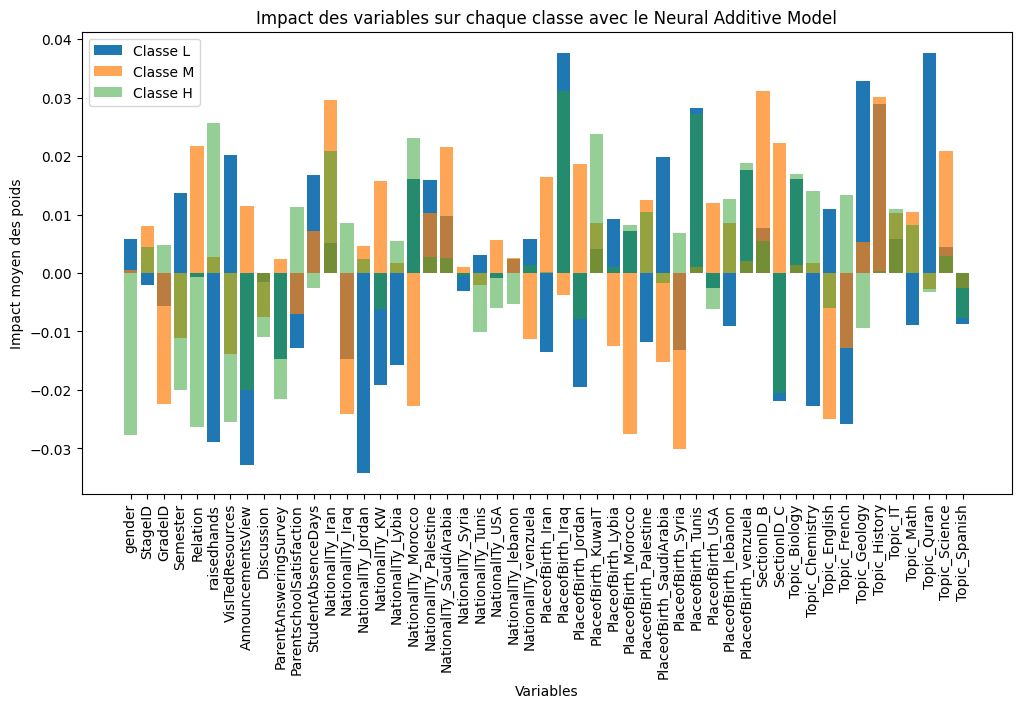

In [83]:
# revoir le code apres pour ne pas avoir à recréer les tensors 
hidden_dim = 35
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.long)

# création du Neural Additive Model corrigé
class NAM(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim=3):
        super(NAM, self).__init__()
        self.subnets = nn.ModuleList([
            nn.Sequential(
                nn.Linear(1, hidden_dim),
                nn.Tanh(), 
                nn.Linear(hidden_dim, output_dim)
            ) for _ in range(input_dim)
        ])

    def forward(self, x):
        outputs = [subnet(x[:, i].view(-1, 1)) for i, subnet in enumerate(self.subnets)]
        return torch.stack(outputs, dim=0).sum(dim=0)  


model = NAM(input_dim, hidden_dim, output_dim=3)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.005)

# phase d entrainement 
epochs = 100
for epoch in range(epochs):
    optimizer.zero_grad()
    outputs = model(X_train_tensor)
    loss = criterion(outputs, y_train_tensor)
    loss.backward()
    optimizer.step()
    
    if epoch % 10 == 0:
        print(f"Epoch [{epoch}/{epochs}], Loss: {loss.item():.4f}")

# phase d evaluation 
model.eval()
with torch.no_grad():
    y_pred = torch.argmax(model(X_test_tensor), dim=1)
    accuracy = (y_pred == y_test_tensor).float().mean().item()
    print(f"Test Accuracy: {accuracy:.4f}")

# recup les poids de sorties uniquement 
feature_importances_per_class = torch.stack([
    subnet[-1].weight.mean(dim=1).detach() for subnet in model.subnets  # Prend la dernière couche de chaque subnet
]) 

feature_importance_mean = feature_importances_per_class.numpy() 

# dans un df on stcoke les val pour chaque classe (c mieux comme ca on visualise d un coup quelles caractéristiques influence comment 
# pour chaque classe en meme temps 
df_importances = pd.DataFrame(feature_importance_mean, 
                              index=actual_feature_names, 
                              columns=["Classe L", "Classe M", "Classe H"])


plt.figure(figsize=(12, 6))
plt.bar(actual_feature_names, feature_importance_mean[:, 0], label="Classe L")  # 0 = L
plt.bar(actual_feature_names, feature_importance_mean[:, 1], label="Classe M", alpha=0.7)  # 1 = M
plt.bar(actual_feature_names, feature_importance_mean[:, 2], label="Classe H", alpha=0.5)  # 2 = H
plt.xticks(rotation=90)
plt.xlabel("Variables")
plt.ylabel("Impact moyen des poids")
plt.title("Impact des variables sur chaque classe avec le Neural Additive Model")
plt.legend()
plt.show()
